In [1]:
!pip install openslide-python openslide-bin
!pip install -U matplotlib
!pip install geopandas
!pip install spectral


In [2]:
import openslide
import matplotlib.pyplot as plt
import geopandas as gpd
                              
                            


(85248, 202752)


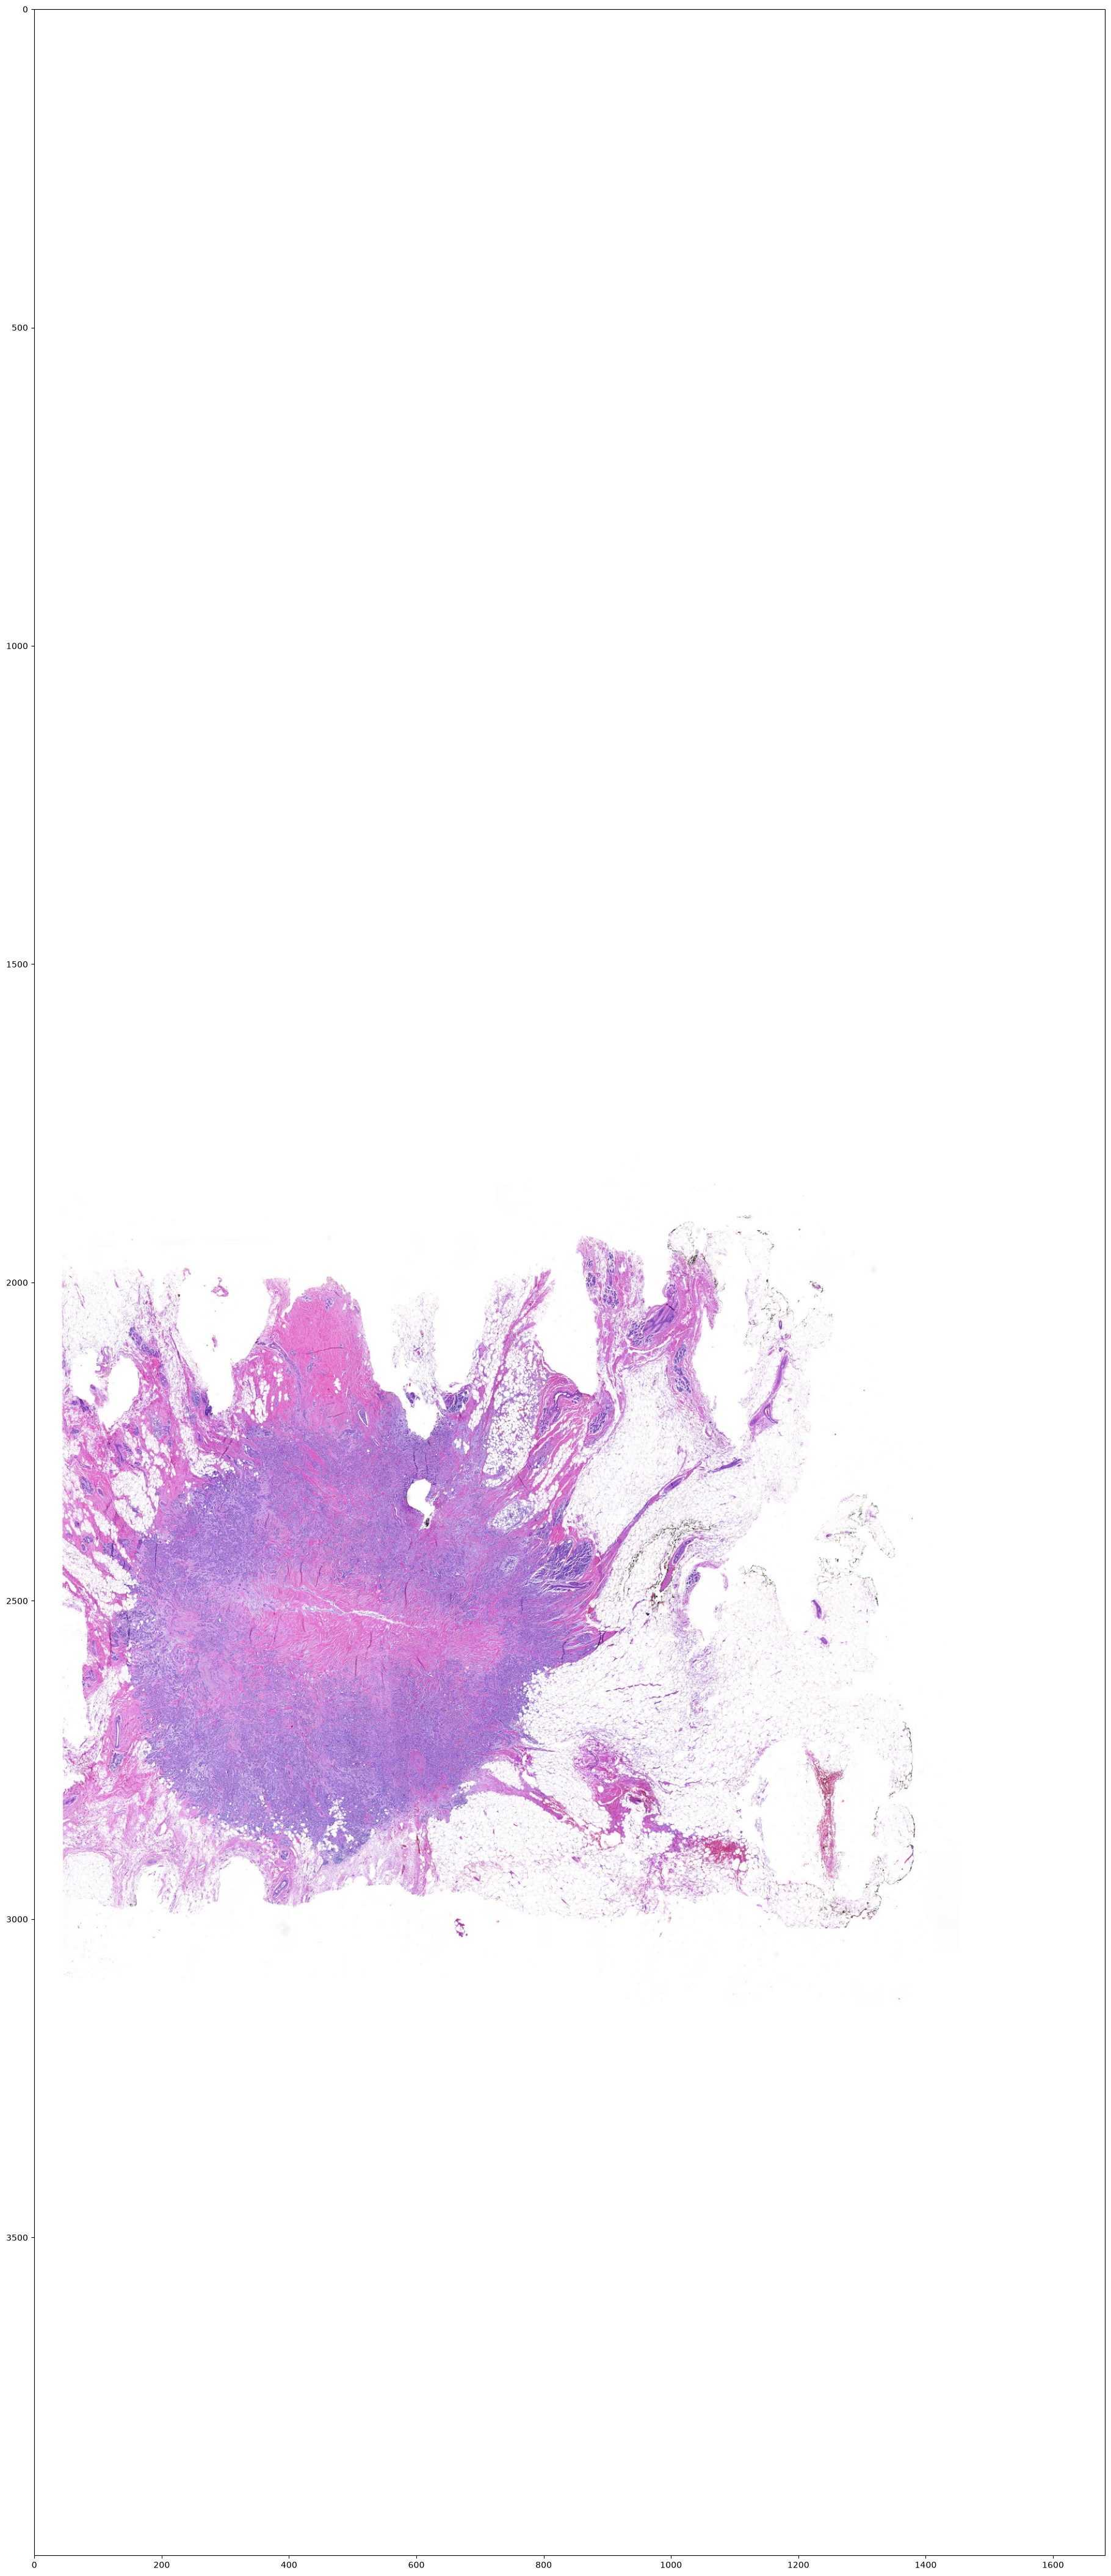

In [3]:
# visualize whole-slide image

slide = openslide.OpenSlide("C:/Users/Abrah/OneDrive/Documents/Patologia Computacional/sample/01_01_Histological_images/43.mrxs")

print(slide.dimensions)

thumbnail = slide.get_thumbnail((4000, 4000))

w, h = thumbnail.size
ratio = h / w

fig, ax = plt.subplots(figsize=(18, 18 * ratio))
ax.imshow(thumbnail)
ax.axis("on")

plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.tight_layout(pad=0)
plt.show()

In [4]:
slide = openslide.OpenSlide("C:/Users/Abrah/OneDrive/Documents/Patologia Computacional/sample/01_01_Histological_images/43.mrxs")
print(slide.dimensions)
print(slide.level_dimensions)  # Ver los niveles de resolución disponibles
print(slide.level_downsamples)  # Ver los factores de reducción de cada nivel

(85248, 202752)
((85248, 202752), (42624, 101376), (21312, 50688), (10656, 25344), (5328, 12672), (2664, 6336), (1332, 3168), (666, 1584), (333, 792), (166, 396))
(1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0, 128.0, 256.0, 512.0)


In [5]:
slide_w, slide_h = slide.dimensions
thumb_w, thumb_h = thumbnail.size

scale_x = slide_w / thumb_w
scale_y = slide_h / thumb_h
print(f"Escala: x={scale_x:.2f}, y={scale_y:.2f}")

# Coordenadas del tumor en la miniatura
x_min_thumb, x_max_thumb = 200, 600
y_min_thumb, y_max_thumb = 2250, 2750

# Convertir al espacio del slide
x_min = int(x_min_thumb * scale_x)
x_max = int(x_max_thumb * scale_x)
y_min = int(y_min_thumb * scale_y)
y_max = int(y_max_thumb * scale_y)
print(f"ROI en slide: x=[{x_min}, {x_max}], y=[{y_min}, {y_max}]")

Escala: x=50.68, y=50.69
ROI en slide: x=[10136, 30409], y=[114048, 139392]


In [6]:
#verificando dimensiones reales
print(f"Dimensiones del slide (w, h): {slide.dimensions}")
print(f"Dimensiones de la miniatura (w, h): {thumbnail.size}")
print(f"Niveles disponibles: {slide.level_dimensions}")

Dimensiones del slide (w, h): (85248, 202752)
Dimensiones de la miniatura (w, h): (1682, 4000)
Niveles disponibles: ((85248, 202752), (42624, 101376), (21312, 50688), (10656, 25344), (5328, 12672), (2664, 6336), (1332, 3168), (666, 1584), (333, 792), (166, 396))


In [7]:
#Extraccion de ROI a menor resolucion de forma robusta
from openslide.deepzoom import DeepZoomGenerator

dz = DeepZoomGenerator(slide, tile_size=256, overlap=0, limit_bounds=False)
print(f"Niveles del DeepZoom: {dz.level_count}")
print(f"Dimensiones por nivel: {dz.level_dimensions}")

Niveles del DeepZoom: 19
Dimensiones por nivel: ((1, 1), (1, 2), (2, 4), (3, 7), (6, 13), (11, 25), (21, 50), (42, 99), (84, 198), (167, 396), (333, 792), (666, 1584), (1332, 3168), (2664, 6336), (5328, 12672), (10656, 25344), (21312, 50688), (42624, 101376), (85248, 202752))


In [8]:
## read anotaciones
gdf = gpd.read_file("C:/Users/Abrah/OneDrive/Documents/Patologia Computacional/sample/01_02_Tissue_Annotations/43.geojson")
print(gdf.head())

   id  objectType name        color  \
0  P1  annotation   P1  [0, 255, 0]   
1  P2  annotation   P2  [0, 255, 0]   
2  P3  annotation   P3  [0, 255, 0]   
3  P4  annotation   P4  [0, 255, 0]   
4  P5  annotation   P5  [0, 255, 0]   

                                    classification  \
0  {'name': 'normal tissue', 'color': [0, 255, 0]}   
1  {'name': 'normal tissue', 'color': [0, 255, 0]}   
2  {'name': 'normal tissue', 'color': [0, 255, 0]}   
3  {'name': 'normal tissue', 'color': [0, 255, 0]}   
4  {'name': 'normal tissue', 'color': [0, 255, 0]}   

                                            geometry  
0  POLYGON ((48209 25862, 48104 26019, 47982 2617...  
1  POLYGON ((52373 24677, 52181 24730, 52007 2478...  
2  POLYGON ((49533 30514, 49428 30671, 49306 3084...  
3  POLYGON ((50352 32744, 50195 32831, 50056 3297...  
4  POLYGON ((18191 59055, 18278 58863, 18365 5867...  


In [9]:
#Visualizar anotaciones
gdf

,id,objectType,name,color,classification,geometry
0,P1,annotation,P1,"[0, 255, 0]","{'name': 'normal tissue', 'color': [0, 255, 0]}","POLYGON ((48209 25862, 48104 26019, 47982 2617..."
1,P2,annotation,P2,"[0, 255, 0]","{'name': 'normal tissue', 'color': [0, 255, 0]}","POLYGON ((52373 24677, 52181 24730, 52007 2478..."
2,P3,annotation,P3,"[0, 255, 0]","{'name': 'normal tissue', 'color': [0, 255, 0]}","POLYGON ((49533 30514, 49428 30671, 49306 3084..."
3,P4,annotation,P4,"[0, 255, 0]","{'name': 'normal tissue', 'color': [0, 255, 0]}","POLYGON ((50352 32744, 50195 32831, 50056 3297..."
4,P5,annotation,P5,"[0, 255, 0]","{'name': 'normal tissue', 'color': [0, 255, 0]}","POLYGON ((18191 59055, 18278 58863, 18365 5867..."
5,P6,annotation,P6,"[0, 255, 0]","{'name': 'normal tissue', 'color': [0, 255, 0]}","POLYGON ((24910 18205, 24562 18727, 24040 1901..."
6,P7,annotation,P7,"[0, 255, 0]","{'name': 'normal tissue', 'color': [0, 255, 0]}","POLYGON ((4489 36770, 4489 36770, 3909 36828, ..."
7,P8,annotation,P8,"[0, 255, 0]","{'name': 'normal tissue', 'color': [0, 255, 0]}","POLYGON ((4605 42282, 4257 42804, 4083 43384, ..."
8,P9,annotation,P9,"[0, 255, 0]","{'name': 'normal tissue', 'color': [0, 255, 0]}","POLYGON ((31524 18495, 30944 18669, 30364 1890..."
9,P10,annotation,P10,"[0, 255, 0]","{'name': 'normal tissue', 'color': [0, 255, 0]}","POLYGON ((38892 17219, 38370 17567, 38196 1814..."


In [10]:
#Las coordenadas del GeoJSON suelen estar expresadas en coordenadas del nivel 0 de la Whole Slide Image, 
# mientras que tu thumbnail está reducido.
# veamos las dimensiones

from shapely.affinity import translate, scale

slide_width, slide_height = slide.dimensions
thumb_width, thumb_height = thumbnail.size

scale_x = thumb_width / slide_width
scale_y = thumb_height / slide_height

bounds_x = int(slide.properties["openslide.bounds-x"])
bounds_y = int(slide.properties["openslide.bounds-y"])

gdf_thumb = gdf.copy()

gdf_thumb["geometry"] = gdf_thumb["geometry"].apply(
    lambda geom: scale(
        translate(
            geom,
            xoff=bounds_x,
            yoff=bounds_y
        ),
        xfact=scale_x,
        yfact=scale_y,
        origin=(0, 0)
    )
)

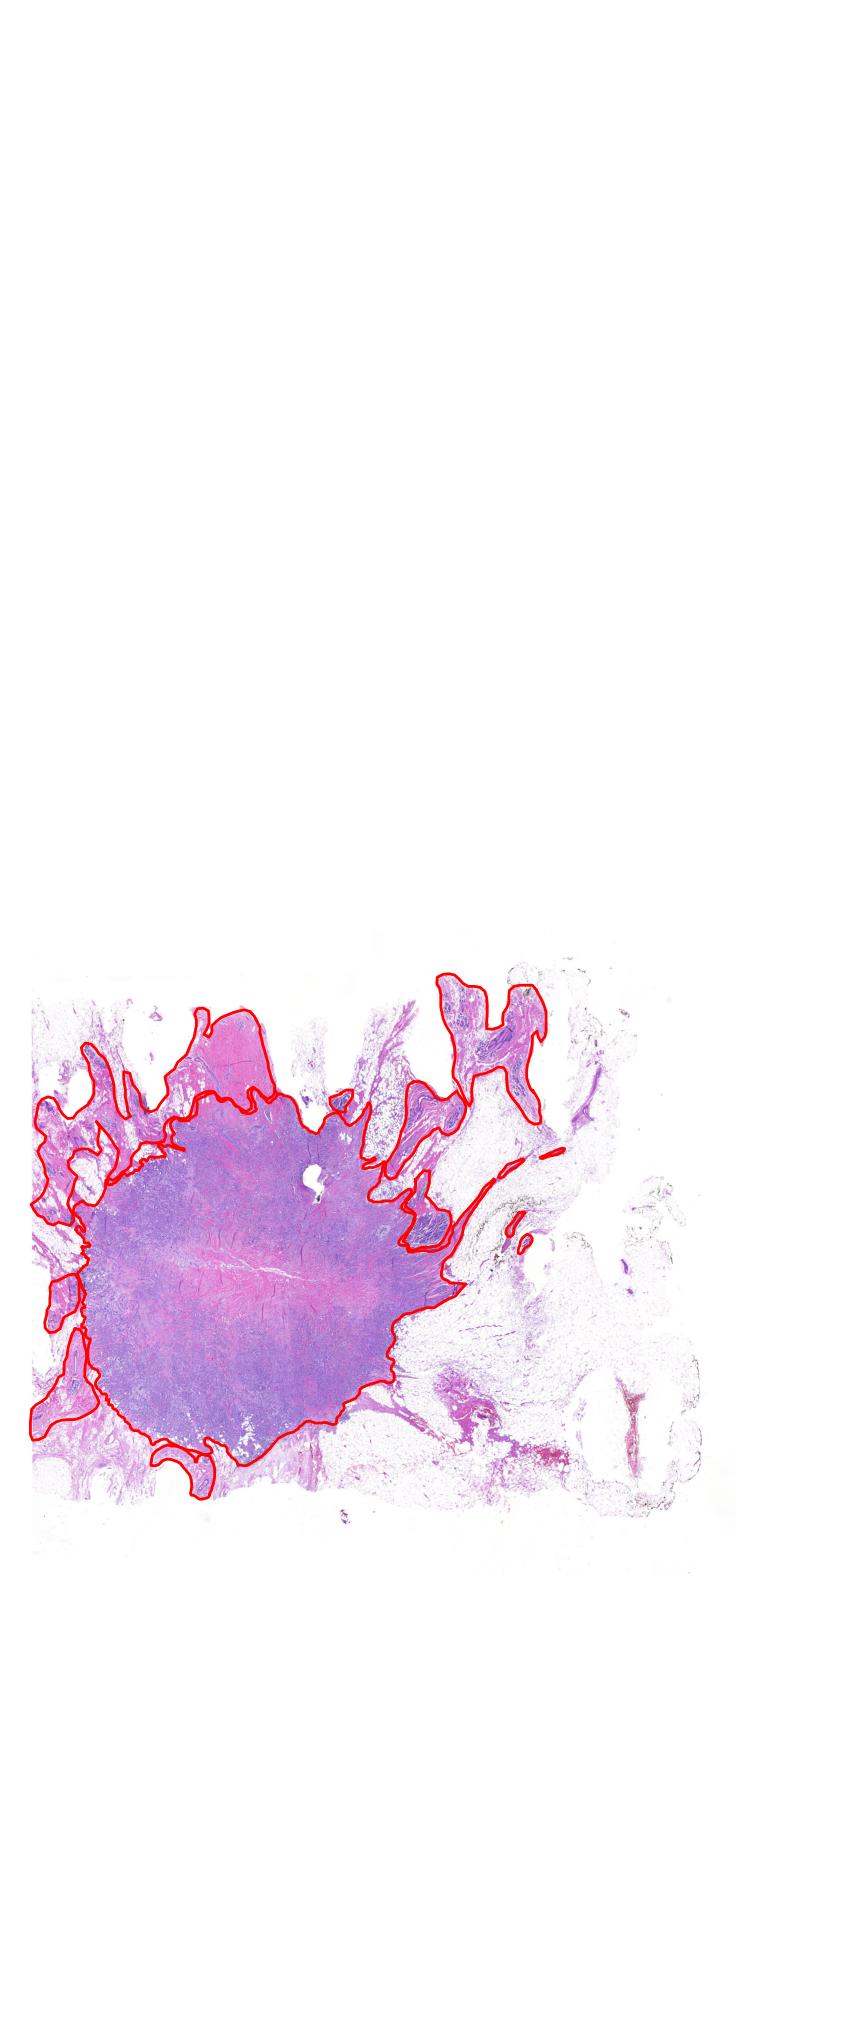

In [11]:
# dibujar los bordes de las anotaciones. Comprobar simetria.
fig, ax = plt.subplots(figsize=(12, 20))

ax.imshow(thumbnail)

gdf_thumb.plot(
    ax=ax,
    facecolor="none",
    edgecolor="red",
    linewidth=2,
    aspect="equal"
)

ax.set_xlim(0, thumbnail.size[0])
ax.set_ylim(thumbnail.size[1], 0)

ax.axis("off")
plt.tight_layout(pad=0)
plt.show()

In [12]:
print(gdf_thumb.columns.tolist())
print(gdf_thumb.shape)
print(gdf_thumb.index)

['id', 'objectType', 'name', 'color', 'classification', 'geometry']
(13, 6)
RangeIndex(start=0, stop=13, step=1)


In [13]:
import json

gdf_thumb["class_name"] = gdf_thumb["classification"].apply(
    lambda x: json.loads(x)["name"] if isinstance(x, str) else x["name"]
)

print(gdf_thumb[["name", "class_name"]])

   name            class_name
0    P1         normal tissue
1    P2         normal tissue
2    P3         normal tissue
3    P4         normal tissue
4    P5         normal tissue
5    P6         normal tissue
6    P7         normal tissue
7    P8         normal tissue
8    P9         normal tissue
9   P10         normal tissue
10  P11         normal tissue
11  P12         normal tissue
12  P13  infiltrant carcinoma


In [14]:
cand = gdf_thumb[gdf_thumb["class_name"] == "infiltrant carcinoma"]
print(f"Anotaciones de carcinoma: {len(cand)}")
print(cand[["name", "class_name"]])

row  = cand.iloc[0]              # o filtra por name si hay varias
geom = row["geometry"]

print(f"\nname      : {row['name']}")
print(f"class_name: {row['class_name']}")
print(f"bounds (thumbnail): {geom.bounds}")   # (minx, miny, maxx, maxy)

Anotaciones de carcinoma: 1
   name            class_name
12  P13  infiltrant carcinoma

name      : P13
class_name: infiltrant carcinoma
bounds (thumbnail): (126.57223629879879, 2157.8085542929293, 969.6044951201201, 2911.3596906565654)


In [15]:
#Pasar a 0
minx_t, miny_t, maxx_t, maxy_t = geom.bounds

x_min = int(minx_t * scale_x)
x_max = int(maxx_t * scale_x)
y_min = int(miny_t * scale_y)
y_max = int(maxy_t * scale_y)

print(f"ROI carcinoma nivel 0: x=[{x_min},{x_max}]  y=[{y_min},{y_max}]")
print(f"region_w, region_h  : {x_max-x_min}, {y_max-y_min}")

ROI carcinoma nivel 0: x=[2,19]  y=[42,57]
region_w, region_h  : 17, 15


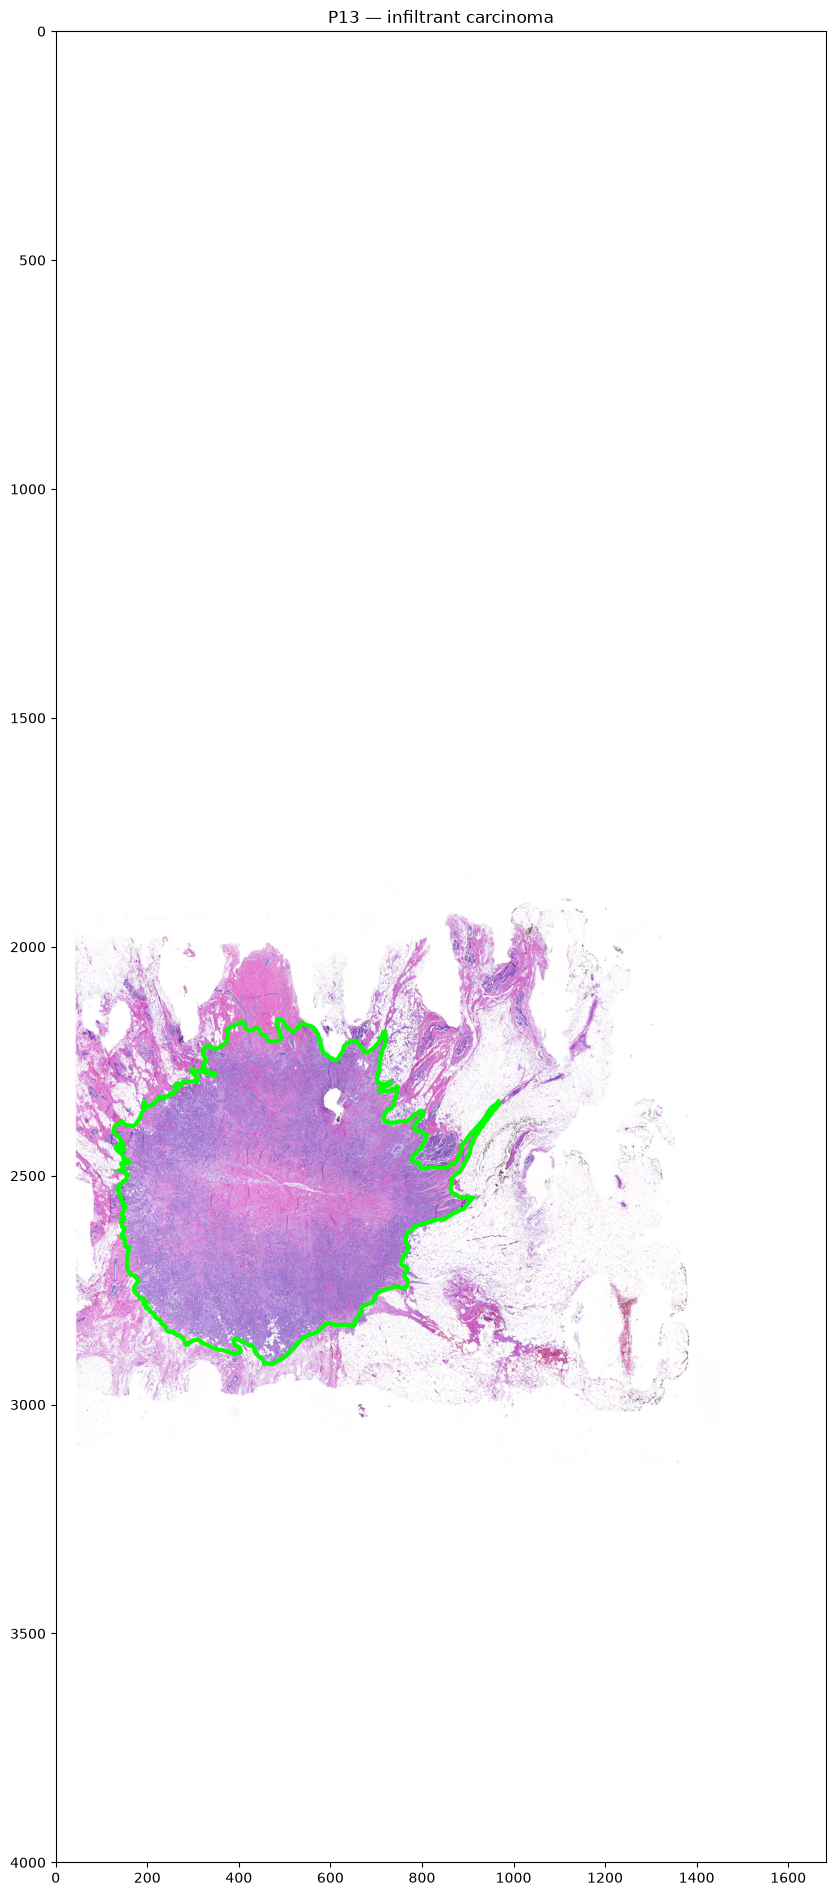

In [16]:
#Verificacion visual

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon

fig, ax = plt.subplots(figsize=(10, 10 * thumbnail.size[1] / thumbnail.size[0]))
ax.imshow(thumbnail)
polys = geom.geoms if geom.geom_type == "MultiPolygon" else [geom]
for p in polys:
    ax.add_patch(MplPolygon(list(p.exterior.coords), closed=True,
                            fill=False, edgecolor="lime", linewidth=3))
ax.set_xlim(0, thumbnail.size[0])
ax.set_ylim(thumbnail.size[1], 0)
ax.set_title(f"{row['name']} — {row['class_name']}")
plt.show()

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from shapely.geometry import box

# --- escalas correctas (miniatura → slide) ---
slide_w, slide_h = slide.dimensions
thumb_w, thumb_h = thumbnail.size

scale_x = slide_w / thumb_w      # ≈ 50.68
scale_y = slide_h / thumb_h      # ≈ 50.68

assert scale_x > 1 and scale_y > 1, "escalas invertidas"

# --- ROI en nivel 0 ---
minx_t, miny_t, maxx_t, maxy_t = geom.bounds

x_min = int(minx_t * scale_x)
x_max = int(maxx_t * scale_x)
y_min = int(miny_t * scale_y)
y_max = int(maxy_t * scale_y)

region_w = x_max - x_min
region_h = y_max - y_min

print(f"scale_x, scale_y : {scale_x:.3f}, {scale_y:.3f}")
print(f"ROI nivel 0      : x=[{x_min},{x_max}]  y=[{y_min},{y_max}]")
print(f"region_w, region_h: {region_w}, {region_h}")

# --- parámetros de parcheo (256×256 @ nivel 3) ---
PATCH_LVL = 256
LEVEL     = 3
FACTOR    = int(slide.level_downsamples[LEVEL])
PATCH_L0  = PATCH_LVL * FACTOR
STEP      = PATCH_L0 // 2

n_rows = max(0, (region_h - PATCH_L0) // STEP + 1)
n_cols = max(0, (region_w - PATCH_L0) // STEP + 1)

print(f"Parche           : {PATCH_L0}px L0 → {PATCH_LVL}px PNG (factor {FACTOR})")
print(f"Step             : {STEP}px")
print(f"Cuadrícula bruta : {n_rows} filas × {n_cols} columnas = {n_rows*n_cols} parches")

scale_x, scale_y : 50.683, 50.688
ROI nivel 0      : x=[6414,49142]  y=[109375,147571]
region_w, region_h: 42728, 38196
Parche           : 2048px L0 → 256px PNG (factor 8)
Step             : 1024px
Cuadrícula bruta : 36 filas × 40 columnas = 1440 parches


In [18]:
print("slide.dimensions   :", slide.dimensions)
print("thumbnail.size     :", thumbnail.size)
print("scale_x, scale_y   :", scale_x, scale_y)
print("geom.bounds        :", geom.bounds)

slide.dimensions   : (85248, 202752)
thumbnail.size     : (1682, 4000)
scale_x, scale_y   : 50.682520808561236 50.688
geom.bounds        : (126.57223629879879, 2157.8085542929293, 969.6044951201201, 2911.3596906565654)


ROI extraída: (5341, 4774)


GEOSException: TopologyException: side location conflict at 534.68073992773202 2168.8097271298934. This can occur if the input geometry is invalid.

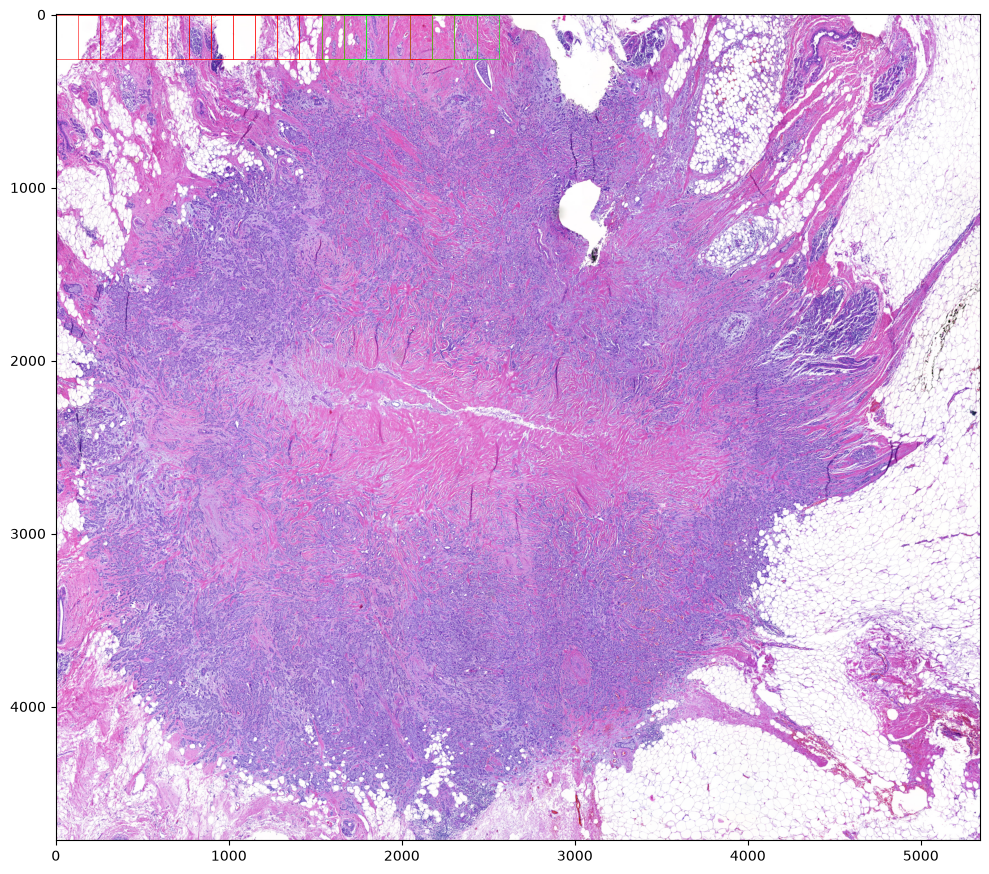

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from shapely.geometry import box

roi_img = slide.read_region(
    (x_min, y_min), LEVEL, (region_w // FACTOR, region_h // FACTOR)
).convert("RGB")
print("ROI extraída:", roi_img.size)

fig, ax = plt.subplots(figsize=(12, 12 * roi_img.size[1] / roi_img.size[0]))
ax.imshow(roi_img)

n_ok = n_tumor = n_white = 0
for y in range(y_min, y_max - PATCH_L0 + 1, STEP):
    for x in range(x_min, x_max - PATCH_L0 + 1, STEP):
        xx = (x - x_min) // FACTOR
        yy = (y - y_min) // FACTOR

        patch_box_thumb = box(
            x / scale_x,              y / scale_y,
            (x + PATCH_L0) / scale_x, (y + PATCH_L0) / scale_y
        )
        frac = patch_box_thumb.intersection(geom).area / patch_box_thumb.area

        if frac < 0.30:
            color, n_tumor = "red", n_tumor + 1
        else:
            arr = np.asarray(slide.read_region(
                (x, y), LEVEL, (PATCH_LVL, PATCH_LVL)
            ).convert("RGB"))
            if arr.mean() > 230 or arr.std() < 8:
                color, n_white = "gray", n_white + 1
            else:
                color, n_ok = "lime", n_ok + 1

        ax.add_patch(Rectangle((xx, yy), PATCH_LVL, PATCH_LVL,
                               fill=False, edgecolor=color, linewidth=0.4))

ax.set_title(f"256×256 @ nivel {LEVEL} | verde={n_ok}  rojo={n_tumor}  gris={n_white}")
ax.axis("off")
plt.show()

In [ ]:
#Anotaciones manuales causan problema
#Diagnosticar y solucionar reconstruyendo el poligono a traves de shapely
#Tambien se puede arreglar a traves de make_valid
from shapely.validation import explain_validity

print("Tipo    :", geom.geom_type)
print("Válido  :", geom.is_valid)
if not geom.is_valid:
    print("Motivo  :", explain_validity(geom))

# Reparación estándar: buffer(0) o make_valid
geom_fixed = geom.buffer(0)       # suele devolver Polygon/MultiPolygon limpio
# alternativa moderna:
# from shapely import make_valid
# geom_fixed = make_valid(geom)

print("Tras fix:", geom_fixed.geom_type, "| válido:", geom_fixed.is_valid)
print("Área antes/después:", geom.area, geom_fixed.area)
print("Bounds antes :", geom.bounds)
print("Bounds después:", geom_fixed.bounds)

In [ ]:
#safe_geom para forzar a que funcione porque intento previo no funciono

def safe_geom(g):
    if g is None or g.is_empty:
        return None
    return g if g.is_valid else g.buffer(0)

geom = safe_geom(geom)

roi_img = slide.read_region(
    (x_min, y_min), LEVEL, (region_w // FACTOR, region_h // FACTOR)
).convert("RGB")
print("ROI extraída:", roi_img.size)

fig, ax = plt.subplots(figsize=(12, 12 * roi_img.size[1] / roi_img.size[0]))
ax.imshow(roi_img)

n_ok = n_tumor = n_white = 0
for y in range(y_min, y_max - PATCH_L0 + 1, STEP):
    for x in range(x_min, x_max - PATCH_L0 + 1, STEP):
        xx = (x - x_min) // FACTOR
        yy = (y - y_min) // FACTOR

        patch_box_thumb = box(
            x / scale_x,              y / scale_y,
            (x + PATCH_L0) / scale_x, (y + PATCH_L0) / scale_y
        )
        frac = patch_box_thumb.intersection(geom).area / patch_box_thumb.area

        if frac < 0.30:
            color, n_tumor = "red", n_tumor + 1
        else:
            arr = np.asarray(slide.read_region(
                (x, y), LEVEL, (PATCH_LVL, PATCH_LVL)
            ).convert("RGB"))
            if arr.mean() > 230 or arr.std() < 8:
                color, n_white = "gray", n_white + 1
            else:
                color, n_ok = "lime", n_ok + 1

        ax.add_patch(Rectangle((xx, yy), PATCH_LVL, PATCH_LVL,
                               fill=False, edgecolor=color, linewidth=0.4))

ax.set_title(f"256×256 @ nivel {LEVEL} | verde={n_ok}  rojo={n_tumor}  gris={n_white}")
ax.axis("off")
plt.show()

In [ ]:
import numpy as np
from shapely.geometry import box

n_total = 0
n_ok    = 0     # verdes: tumor suficiente + no fondo blanco
n_tumor = 0     # rojas: <30% tumor
n_white = 0     # grises: mucho blanco o poca textura

for y in range(y_min, y_max - PATCH_L0 + 1, STEP):
    for x in range(x_min, x_max - PATCH_L0 + 1, STEP):
        n_total += 1

        patch_box_thumb = box(
            x / scale_x,              y / scale_y,
            (x + PATCH_L0) / scale_x, (y + PATCH_L0) / scale_y
        )
        frac = patch_box_thumb.intersection(geom).area / patch_box_thumb.area

        if frac < 0.30:
            n_tumor += 1
            continue

        arr = np.asarray(slide.read_region(
            (x, y), LEVEL, (PATCH_LVL, PATCH_LVL)
        ).convert("RGB"))

        if arr.mean() > 230 or arr.std() < 8:
            n_white += 1
        else:
            n_ok += 1

print(f"Parches totales en la cuadrícula : {n_total}")
print(f"  ✅ verdes (se guardarían)      : {n_ok}")
print(f"  🔴 rojas (poco tumor <30%)     : {n_tumor}")
print(f"  ⚪ grises (fondo blanco)        : {n_white}")
print(f"  suma                           : {n_ok + n_tumor + n_white}")

import albumentations as A
import cv2

# Augmentation moderada para Prov-GigaPath / patología
# - Sin Resize (rompe 224x224 y mete artefactos)
# - Sin Shifting (shift 0.4 saca el tumor del parche)
# - Con VerticalFlip (seguro en patología, sin orientación canónica)
train_aug = A.Compose([
    # --- geométricas seguras (sin shift, sin resize) ---
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),                      # 90/180/270, sin pérdida de píxeles
    A.Rotate(limit=15, border_mode=cv2.BORDER_REFLECT_101, p=0.3),

    # --- scaling suave (no el 0.4-1.3 del paper) ---
    A.RandomScale(scale_limit=(-0.1, 0.1), p=0.3),

    # --- variación de color / tinción H&E ---
    A.ColorJitter(brightness=0.1, contrast=0.1,
                  saturation=0.05, hue=0.02, p=0.4),
    A.RandomGamma(gamma_limit=(80, 120), p=0.3),  # γ ∈ [0.8, 1.2]

    # --- ruido / desenfoque (simula artefactos de escáner) ---
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.GaussNoise(var_limit=(5.0, 20.0), p=0.15),

    # --- deformación elástica suave (morfología tisular) ---
    A.ElasticTransform(alpha=1, sigma=50, alpha_affine=50,
                       border_mode=cv2.BORDER_REFLECT_101, p=0.2),
])


!!!!No correr offline PC morirá!!!!